# Кластеризация городов методом DBSCAN

Лабораторная работа по кластерному анализу. Датасет Economics of Cities: 48 городов мира, 1991 год.

## 1. Постановка задачи

DBSCAN ищет плотные области в пространстве признаков и не требует заранее задавать число кластеров. Объекты, не попавшие ни в одну плотную область, получают метку шума. Нужно выяснить, есть ли в данных о городах устойчивая плотностная структура по трём показателям: `Work`, `Price` и `Salary`, и какой ценой (то есть сколькими городами, отнесёнными к шуму) она находится.

Параметры `eps` и `min_samples` подбираются систематически: строятся k-distance графики, затем перебирается сетка значений. Выбор параметров не сводится к максимуму одной метрики, так как метрики считаются только на не-шумовых наблюдениях и поэтому тем выше, чем больше трудных городов алгоритм объявил шумом. Отдельно проверяется вариант `eps=0.75`, `min_samples=4` и его ближайшие соседи. Если устойчивой структуры нет, это нужно прямо сказать.

Ноутбук самостоятельный: чтобы его выполнить, нужен только файл `Econom_Cities_data.csv` рядом с ним.

Подключаем библиотеки и задаём константы. Единые названия признаков и список метрик объявлены один раз, чтобы дальше не повторять их в коде.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.spatial.distance import cdist, pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_samples,
                             silhouette_score)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

DATA_PATH = 'Econom_Cities_data.csv'
MISSING_CODE = -9999
FEATURES = ['Work', 'Price', 'Salary']
METRIC_COLUMNS = [
    'silhouette', 'davies_bouldin', 'calinski_harabasz', 'dunn'
]
RANDOM_STATE = 42

## 2. Описание данных

Файл `Econom_Cities_data.csv` содержит 48 городов мира и три числовых показателя за 1991 год:

| Признак | Смысл |
|---|---|
| `Work` | годовая рабочая нагрузка (порядок значений 1600-2400 соответствует числу рабочих часов в год) |
| `Price` | уровень цен на потребительскую корзину, индекс |
| `Salary` | уровень оплаты труда, индекс (максимум 100 у Цюриха) |

Единицы измерения в самом файле не описаны, поэтому `Price` и `Salary` трактуются как относительные индексы, а все выводы о «высоких» и «низких» значениях носят сравнительный характер.

Столбец `City` служит только для идентификации наблюдений и подписей на графиках. В расчёт расстояний он не входит.

В файле три технические особенности: столбцы разделены символом `;`, десятичным разделителем служит запятая, а пропуски закодированы числом `-9999`. Если оставить это число как есть, оно станет огромным выбросом и полностью исказит расстояния, поэтому на этапе загрузки его нужно заменить на настоящий пропуск.

## 3. Предобработка данных

Сначала загружаем файл с правильными разделителями и смотрим, сколько значений `-9999` содержит каждый признак.

In [2]:
raw = pd.read_csv(DATA_PATH, sep=';', decimal=',')
print(f'Строк: {raw.shape[0]}, столбцов: {raw.shape[1]}')
print(raw.dtypes, end='\n\n')

missing_mask = raw[FEATURES].eq(MISSING_CODE)
print('Количество значений -9999 по признакам:')
print(missing_mask.sum(), end='\n\n')
raw[missing_mask.any(axis=1)]

Строк: 48, столбцов: 4
City          str
Work        int64
Price     float64
Salary    float64
dtype: object

Количество значений -9999 по признакам:
Work      2
Price     0
Salary    2
dtype: int64



,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


Пропуски есть у двух городов, Каира и Джакарты, и у обоих отсутствуют сразу `Work` и `Salary`. Остаётся один признак из трёх (`Price`). Заполнять два недостающих показателя по одному оставшемуся было бы выдумыванием данных: любая оценка зарплаты и рабочей нагрузки по цене скрыла бы как раз ту информацию, ради которой строится кластеризация. Среднее или медиана по выборке притянули бы оба города к центру облака и исказили бы расстояния. Поэтому эти два города исключаются из основной модели, а не восстанавливаются. Потеря небольшая: 2 из 48 наблюдений.

In [3]:
data = raw.replace(MISSING_CODE, np.nan)
clean = data.dropna(subset=FEATURES).reset_index(drop=True)
excluded = sorted(set(data['City']) - set(clean['City']))
print(f'Исключено городов: {len(excluded)} ({", ".join(excluded)})')
print(f'В анализе: {len(clean)} городов')

Исключено городов: 2 (Cairo, Jakarta)
В анализе: 46 городов


Теперь проверяем, нет ли повторяющихся строк и названий, и смотрим базовые характеристики признаков в исходных единицах. Эти цифры понадобятся позже, чтобы сопоставлять профили кластеров с общим фоном.

In [4]:
print('Полных дубликатов строк:', raw.duplicated().sum())
print('Повторяющихся названий городов:', raw['City'].duplicated().sum())
print('Дубликатов по значениям признаков:',
      clean.duplicated(subset=FEATURES).sum())
clean[FEATURES].describe().round(2)

Полных дубликатов строк: 0
Повторяющихся названий городов: 0
Дубликатов по значениям признаков: 0


,Work,Price,Salary
count,46.00,46.00,46.00
mean,1879.91,70.10,39.55
std,174.34,21.39,24.76
min,1583.00,30.30,2.70
25%,1745.25,51.78,14.38
50%,1849.00,70.95,43.65
75%,1976.25,81.90,59.70
max,2375.00,115.50,100.00


Признаки измеряются в разных масштабах: `Work` меняется в тысячах, а `Price` и `Salary` в десятках. Без стандартизации евклидово расстояние определялось бы почти только `Work`. `StandardScaler` приводит каждый признак к нулевому среднему и единичному стандартному отклонению, и все три показателя вносят в расстояние сопоставимый вклад. Кластеризация далее выполняется на этих трёх стандартизированных признаках.

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(clean[FEATURES])
print('Средние:', X.mean(axis=0).round(3))
print('Стандартные отклонения:', X.std(axis=0).round(3))

Средние: [ 0. -0.  0.]
Стандартные отклонения: [1. 1. 1.]


## 4. Разведочный анализ

Смотрим распределения признаков, связи между ними и общую геометрию облака точек. От этого зависит, чего ожидать от кластеризации: есть ли выбросы, насколько признаки дублируют друг друга и можно ли показать данные на плоскости без заметной потери информации.

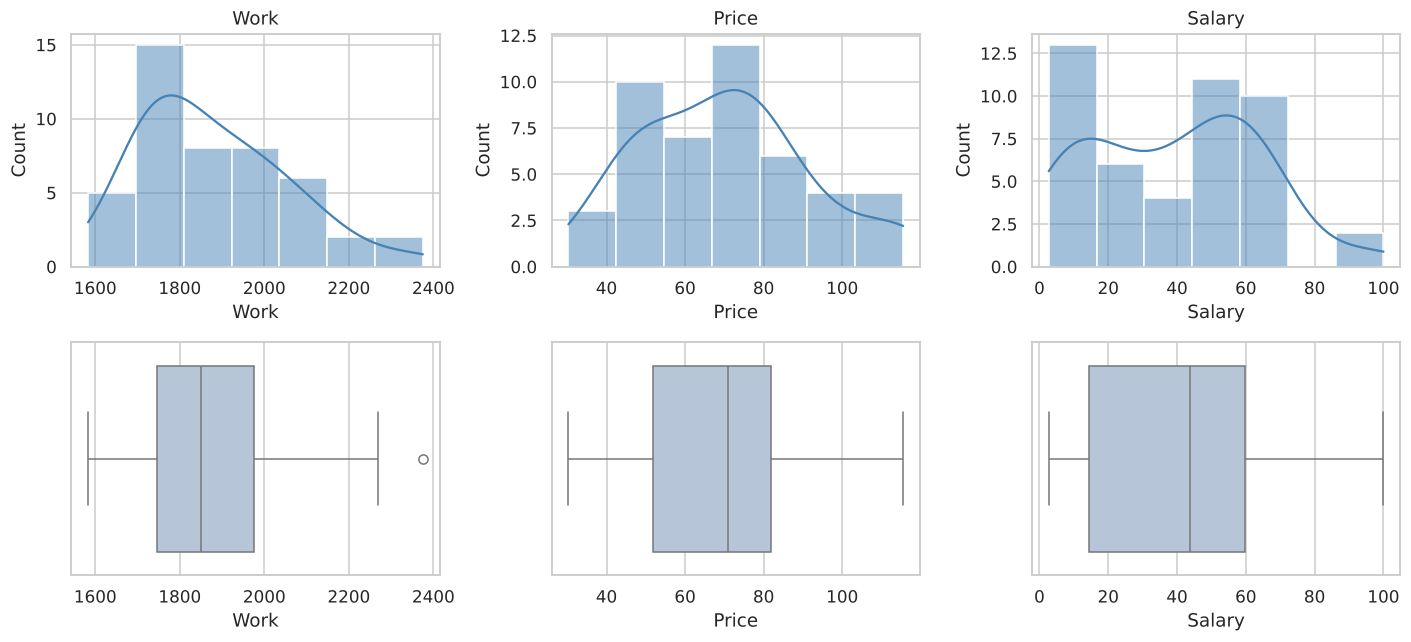

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for col, feature in enumerate(FEATURES):
    sns.histplot(clean[feature], kde=True, ax=axes[0, col],
                 color='steelblue')
    sns.boxplot(x=clean[feature], ax=axes[1, col], color='lightsteelblue')
    axes[0, col].set_title(feature)
plt.tight_layout()
plt.show()

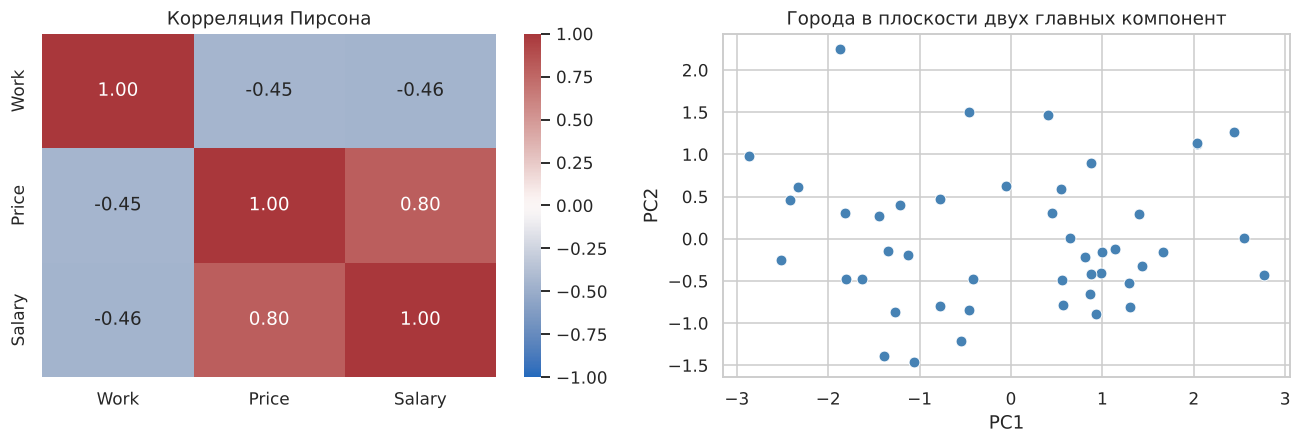

Доля дисперсии PC1 и PC2: [0.72  0.215]
Суммарно: 0.935


,PC1,PC2
Work,-0.48,0.87
Price,0.62,0.35
Salary,0.62,0.34


In [7]:
corr = clean[FEATURES].corr()
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_coords = pca.fit_transform(X)
loadings = pd.DataFrame(pca.components_.T, index=FEATURES,
                        columns=['PC1', 'PC2']).round(2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1,
            ax=axes[0])
axes[0].set_title('Корреляция Пирсона')
sns.scatterplot(x=pca_coords[:, 0], y=pca_coords[:, 1], ax=axes[1],
                color='steelblue', s=50)
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('Города в плоскости двух главных компонент')
plt.tight_layout()
plt.show()

print('Доля дисперсии PC1 и PC2:', pca.explained_variance_ratio_.round(3))
print('Суммарно:', pca.explained_variance_ratio_.sum().round(3))
loadings

Что видно из этих графиков и расчётов:

- Распределение `Work` скошено вправо (коэффициент асимметрии около 0,77): основная масса городов работает 1700-2000 часов в год, а несколько городов заметно выше. Для `Salary` и `Price` асимметрия слабее.
- `Price` и `Salary` сильно связаны (корреляция около 0,80). `Work` отрицательно связан с обоими показателями (около -0,45): чем выше нагрузка, тем в среднем ниже и цены, и зарплаты.
- Две первые главные компоненты объясняют примерно 93 % дисперсии, поэтому проекция на плоскость почти не теряет структуру. PC1 в основном противопоставляет «дорогие и высокооплачиваемые» города «дешёвым и малооплачиваемым» и в первую очередь опирается на `Price` и `Salary`, а PC2 в основном отражает `Work`.

Сильная связь `Price` и `Salary` означает, что эти два признака частично дублируют друг друга и «вес» этой оси в расстоянии выше, чем у `Work`. Это стоит помнить при интерпретации. PCA используется только для рисунков: все модели обучаются на трёх исходных стандартизированных признаках.

## 5. Теоретическое описание метода

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) опирается на два параметра:

- `eps` - радиус окрестности вокруг объекта;
- `min_samples` - минимальное число объектов в окрестности (включая сам объект), при котором точка считается плотной.

Все объекты делятся на три типа. **Ядровая точка** имеет в своей окрестности не меньше `min_samples` объектов. **Граничная точка** сама не ядровая, но попадает в окрестность ядровой. **Шум** - всё остальное. Кластером становится множество ядровых точек, связанных цепочкой пересекающихся окрестностей, вместе с их граничными точками.

Следствия, важные для этой работы:

- число кластеров определяется данными, а не задаётся;
- форма кластеров не обязана быть выпуклой;
- выбросы честно маркируются как шум, а не вынужденно приписываются к какой-либо группе;
- единый `eps` предполагает примерно одинаковую плотность всех кластеров, и если плотность различается, подобрать один подходящий радиус нельзя;
- результат может резко меняться при небольшом изменении `eps`, особенно на малой выборке.

**Метрики и шум.** Метки шума `-1` не образуют кластера: это «не удалось отнести ни к одному». Если включить их в расчёт как кластер, метрики потеряют смысл, поэтому Silhouette, Davies-Bouldin, Calinski-Harabasz и Dunn считаются только на не-шумовых наблюдениях и только когда найдено не менее двух кластеров. Эти значения нельзя напрямую сравнивать с метриками Ward и K-means, рассчитанными на всех городах, потому что DBSCAN отбрасывает именно самые трудные для разбиения объекты.


### Метрики качества

Для оценки разбиений применяются четыре внутренних индекса. Они опираются на разные свойства кластеров, и их значения нельзя сводить в один общий рейтинг.

| Метрика | Что измеряет | Как читать |
|---|---|---|
| Silhouette | для каждого объекта сравнивает среднее расстояние до своего кластера и до ближайшего чужого; затем усредняется | от -1 до 1, чем выше, тем лучше |
| Davies-Bouldin | среднюю «похожесть» каждого кластера на самого близкого соседа: отношение суммарного разброса к расстоянию между центрами | чем ниже, тем лучше |
| Calinski-Harabasz | отношение межкластерной дисперсии к внутрикластерной с поправкой на число кластеров | чем выше, тем лучше |
| Dunn | наименьшее расстояние между двумя кластерами, делённое на наибольший диаметр кластера | чем выше, тем лучше |

Особенности, важные для интерпретации. Calinski-Harabasz и Davies-Bouldin неявно ориентированы на компактные округлые кластеры. Dunn зависит только от двух экстремальных расстояний, поэтому один необычный город заметно меняет его значение. Silhouette полезен ещё и тем, что даёт оценку для каждого города, а не только общую. Все четыре индекса не учитывают содержательный смысл групп, поэтому дополнительно рассматриваются размеры кластеров и профили в исходных единицах.

## 6. Обоснование выбора параметров

**min_samples.** Рассматриваются значения 3, 4, 5 и 6. При 46 городах большие значения сделают почти любую группу «недостаточно плотной», а значение меньше 3 превращает метод в связывание по ближайшему соседу.

**eps.** Ориентиром служит k-distance график: для каждой точки берётся расстояние до `min_samples`-го ближайшего объекта (считая саму точку), значения сортируются. Радиус около «колена» этого графика отделяет точки в плотных областях от изолированных. Затем `eps` перебирается на сетке от 0,30 до 1,50 с шагом 0,05, чтобы увидеть, как решение меняется вокруг найденной области.

**Допустимая доля шума.** Решение, при котором шумом объявлено больше пятой части городов (более 9 из 46), в этой работе не считается пригодным для содержательного вывода: модель в этом случае описывает меньшинство городов. Порог 20 % - договорённость, а не стандарт, и он будет проверяться на устойчивость выводов. Дополнительно требуется не менее двух кластеров и не менее 5 городов в самом малом из них, иначе кластер не отличить от случайной группы.

Сначала подключаем вспомогательные функции.

Собираем функции, которые будут вызываться много раз. Индекс Данна в `scikit-learn` отсутствует, поэтому он реализован самостоятельно через матрицы попарных расстояний: `pdist` даёт диаметры кластеров, `cdist` даёт расстояния между объектами разных кластеров.

In [8]:
def dunn_index(points, labels):
    groups = [points[labels == c] for c in np.unique(labels)]
    max_diameter = max(
        pdist(group).max() if len(group) > 1 else 0.0 for group in groups
    )
    min_separation = min(
        cdist(first, second).min()
        for i, first in enumerate(groups)
        for second in groups[i + 1:]
    )
    return min_separation / max_diameter


def evaluate_partition(points, labels):
    return {
        'silhouette': silhouette_score(points, labels),
        'davies_bouldin': davies_bouldin_score(points, labels),
        'calinski_harabasz': calinski_harabasz_score(points, labels),
        'dunn': dunn_index(points, labels),
    }


def format_sizes(labels):
    counts = pd.Series(labels).value_counts().sort_values(ascending=False)
    return ' / '.join(str(n) for n in counts.values)

In [9]:
def relabel_by_salary(labels, salary):
    order = pd.Series(salary).groupby(labels).mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order, start=1)}
    return np.array([mapping[label] for label in labels])


def cluster_profile(frame, labels):
    grouped = frame.assign(cluster=labels).groupby('cluster')[FEATURES]
    profile = pd.concat([
        grouped.size().rename('n'),
        grouped.mean().round(1).add_suffix('_mean'),
        grouped.median().round(1).add_suffix('_median'),
    ], axis=1)
    return profile


def print_cities(frame, labels):
    names = frame['City'].str.replace('_', ' ')
    for cluster, group in names.groupby(labels):
        title = 'Шум' if cluster == -1 else f'Кластер {cluster}'
        print(f'  {title} ({len(group)}): {", ".join(group)}')


def weak_cities(frame, points, labels, threshold=0.25):
    table = pd.DataFrame({
        'city': frame['City'].str.replace('_', ' '),
        'cluster': labels,
        'silhouette': silhouette_samples(points, labels).round(3),
    })
    return table[table['silhouette'] < threshold].sort_values('silhouette')


def silhouette_summary(points, labels):
    values = silhouette_samples(points, labels)
    return pd.DataFrame({'cluster': labels, 'value': values}).groupby(
        'cluster')['value'].agg(
        n='size', mean='mean', min='min',
        below_zero=lambda s: int((s < 0).sum()),
        below_025=lambda s: int((s < 0.25).sum()),
    ).round(3)

In [10]:
def plot_clusters(ax, labels, title, annotate=True):
    palette = sns.color_palette('Set2', 8)
    for cluster in np.unique(labels):
        mask = labels == cluster
        if cluster == -1:
            ax.scatter(pca_coords[mask, 0], pca_coords[mask, 1], s=55,
                       color='gray', marker='x', label='Шум')
        else:
            ax.scatter(pca_coords[mask, 0], pca_coords[mask, 1], s=60,
                       color=palette[cluster - 1], edgecolor='white',
                       label=f'Кластер {cluster}')
    if annotate:
        names = clean['City'].str.replace('_', ' ')
        for (x_pos, y_pos), name in zip(pca_coords, names):
            ax.annotate(name, (x_pos, y_pos), fontsize=7.5,
                        xytext=(3, 3), textcoords='offset points')
    ratio = pca.explained_variance_ratio_
    ax.set_xlabel(f'PC1 ({ratio[0]:.0%})')
    ax.set_ylabel(f'PC2 ({ratio[1]:.0%})')
    ax.set_title(title)
    ax.legend(loc='best', fontsize=8)


def plot_feature_boxes(labels, suptitle):
    frame = clean.assign(cluster=labels)
    base = sns.color_palette('Set2', 8)
    palette = {
        cluster: 'gray' if cluster == -1 else base[cluster - 1]
        for cluster in np.unique(labels)
    }
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, feature in zip(axes, FEATURES):
        sns.boxplot(data=frame, x='cluster', y=feature, hue='cluster',
                    palette=palette, legend=False, ax=ax)
        sns.stripplot(data=frame, x='cluster', y=feature, color='black',
                      size=3, alpha=0.6, ax=ax)
        ax.set_title(feature)
    fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

Строим k-distance графики для всех рассматриваемых `min_samples`. Расстояние считается до `min_samples`-го соседа с учётом самой точки: именно такое расстояние определяет, станет ли точка ядровой при данном `eps`. Горизонтальная линия отмечает `eps=0.75`, которое требуется проверить отдельно.

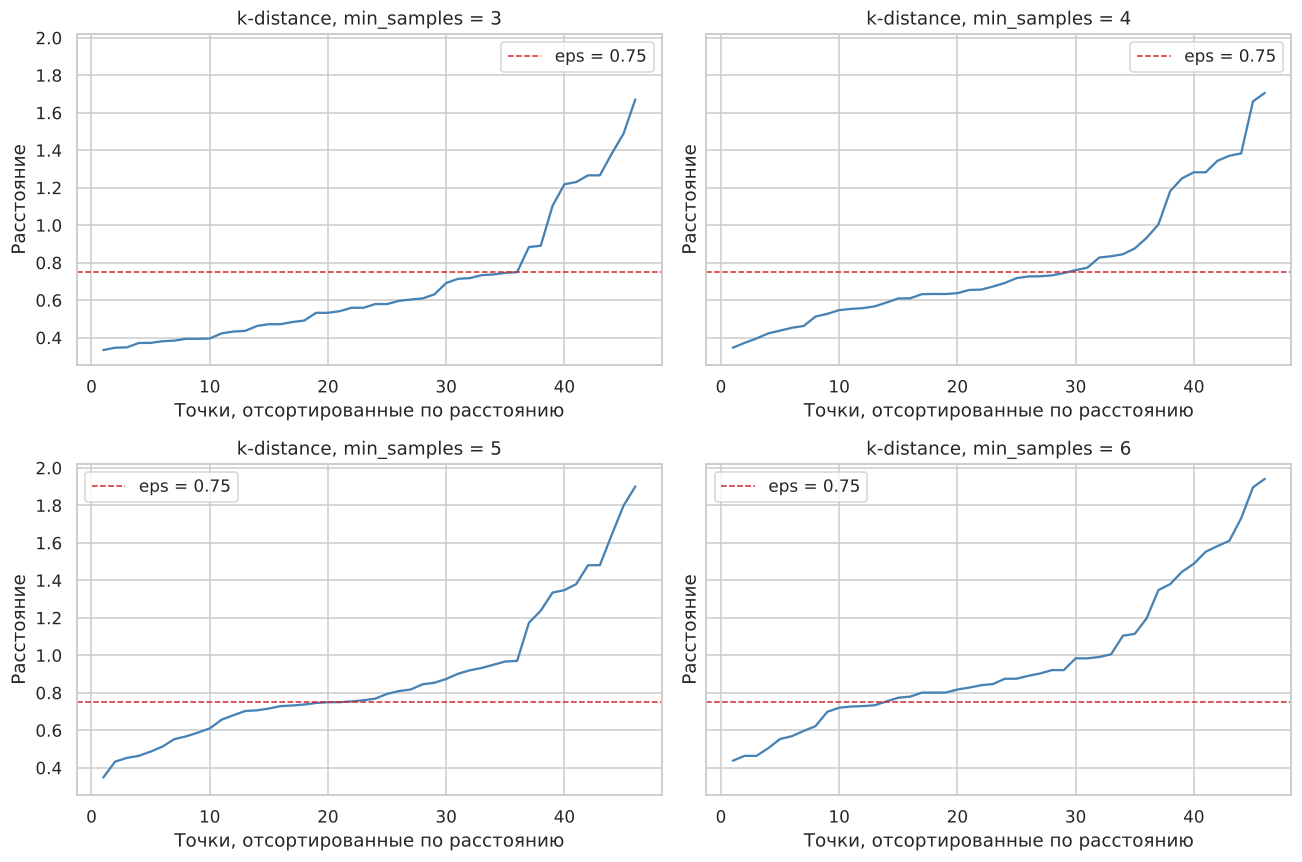

In [11]:
MIN_SAMPLES_GRID = [3, 4, 5, 6]
EPS_GRID = np.round(np.arange(0.30, 1.501, 0.05), 2)
FOCUS_EPS = 0.75
FOCUS_MIN_SAMPLES = 4
NOISE_LIMIT = 0.20
MIN_CLUSTER_SIZE = 5


def k_distances(points, k):
    neighbors = NearestNeighbors(n_neighbors=k).fit(points)
    distances, _ = neighbors.kneighbors(points)
    return np.sort(distances[:, -1])


fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, min_samples in zip(axes.ravel(), MIN_SAMPLES_GRID):
    values = k_distances(X, min_samples)
    ax.plot(np.arange(1, len(values) + 1), values, color='steelblue')
    ax.axhline(FOCUS_EPS, ls='--', color='tab:red', lw=1,
               label=f'eps = {FOCUS_EPS}')
    ax.set_title(f'k-distance, min_samples = {min_samples}')
    ax.set_xlabel('Точки, отсортированные по расстоянию')
    ax.set_ylabel('Расстояние')
    ax.legend()
plt.tight_layout()
plt.show()

Как читать графики. Для `min_samples=3` кривая медленно растёт примерно до 0,75, затем резко идёт вверх около 0,9: колено расположено в области 0,75-0,9. Для `min_samples=4` изгиб находится около 0,8-0,9. Для `min_samples=5` есть площадка около 0,75-0,8 и подъём после 1,0. При `min_samples=6` выраженного колена нет, кривая растёт плавно. Таким образом, область `eps` порядка 0,75-0,9 выглядит правдоподобным кандидатом для 3-5 соседей, а для 6 соседей ориентира нет. Это только подсказка: окончательный выбор делается по сетке параметров ниже, потому что на 46 точках колено определяется неоднозначно.

## 7. Построение модели

Для каждого сочетания `min_samples` и `eps` запускается DBSCAN на трёх стандартизированных признаках. Фиксируются число кластеров, число шумовых городов, доля шума, размеры кластеров и четыре метрики на не-шумовых наблюдениях (только если найдено хотя бы два кластера). Метки кластеров упорядочены по возрастанию средней зарплаты, шум имеет метку `-1`.

In [12]:
def relabel_clusters(labels, salary):
    mask = labels != -1
    result = labels.copy()
    result[mask] = relabel_by_salary(labels[mask], salary[mask])
    return result


def run_dbscan(points, eps, min_samples):
    raw_labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(points)
    labels = relabel_clusters(raw_labels, clean['Salary'].values)
    mask = labels != -1
    n_clusters = len(np.unique(labels[mask]))
    row = {
        'eps': eps,
        'min_samples': min_samples,
        'n_clusters': n_clusters,
        'n_noise': int((~mask).sum()),
        'noise_share': (~mask).mean(),
        'min_cluster_size': (int(np.bincount(labels[mask])[1:].min())
                             if n_clusters else 0),
        'sizes': format_sizes(labels[mask]) if n_clusters else '-',
    }
    if n_clusters >= 2:
        row.update(evaluate_partition(points[mask], labels[mask]))
    return row, labels


partitions = {}
rows = []
for min_samples in MIN_SAMPLES_GRID:
    for eps in EPS_GRID:
        row, labels = run_dbscan(X, eps, min_samples)
        partitions[(eps, min_samples)] = labels
        rows.append(row)
grid = pd.DataFrame(rows)
grid['partition_id'] = pd.Series(
    [partitions[(e, m)].tobytes() for e, m in zip(grid['eps'],
                                                  grid['min_samples'])]
).factorize()[0]
print(f'Рассмотрено сочетаний параметров: {len(grid)}')
print(f'Из них с найденными двумя и более кластерами: '
      f'{(grid["n_clusters"] >= 2).sum()}')

Рассмотрено сочетаний параметров: 100
Из них с найденными двумя и более кластерами: 33


## 8. Оценка качества кластеризации

Сначала смотрим, как число кластеров и доля шума зависят от `eps`. Это главный показатель того, есть ли у решения вообще устойчивая структура.

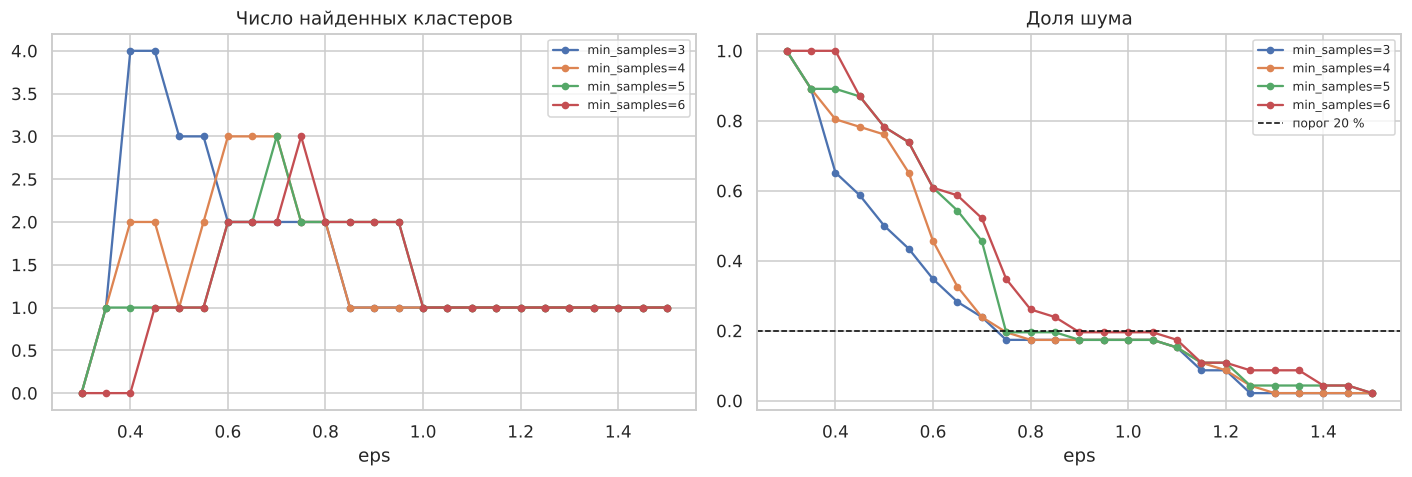

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for min_samples, subset in grid.groupby('min_samples'):
    axes[0].plot(subset['eps'], subset['n_clusters'], marker='o', ms=4,
                 label=f'min_samples={min_samples}')
    axes[1].plot(subset['eps'], subset['noise_share'], marker='o', ms=4,
                 label=f'min_samples={min_samples}')
axes[0].set_title('Число найденных кластеров')
axes[1].set_title('Доля шума')
axes[1].axhline(NOISE_LIMIT, ls='--', color='black', lw=1,
                label='порог 20 %')
for ax in axes:
    ax.set_xlabel('eps')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Теперь метрики качества на не-шумовых наблюдениях. Заполненные маркеры - решения, где шум не превышает 20 %. Полые маркеры - решения с большей долей шума: их значения рассчитаны на небольшой «чистой» части данных и легко вводят в заблуждение. Линия прерывается там, где найдено меньше двух кластеров и метрики не определены.

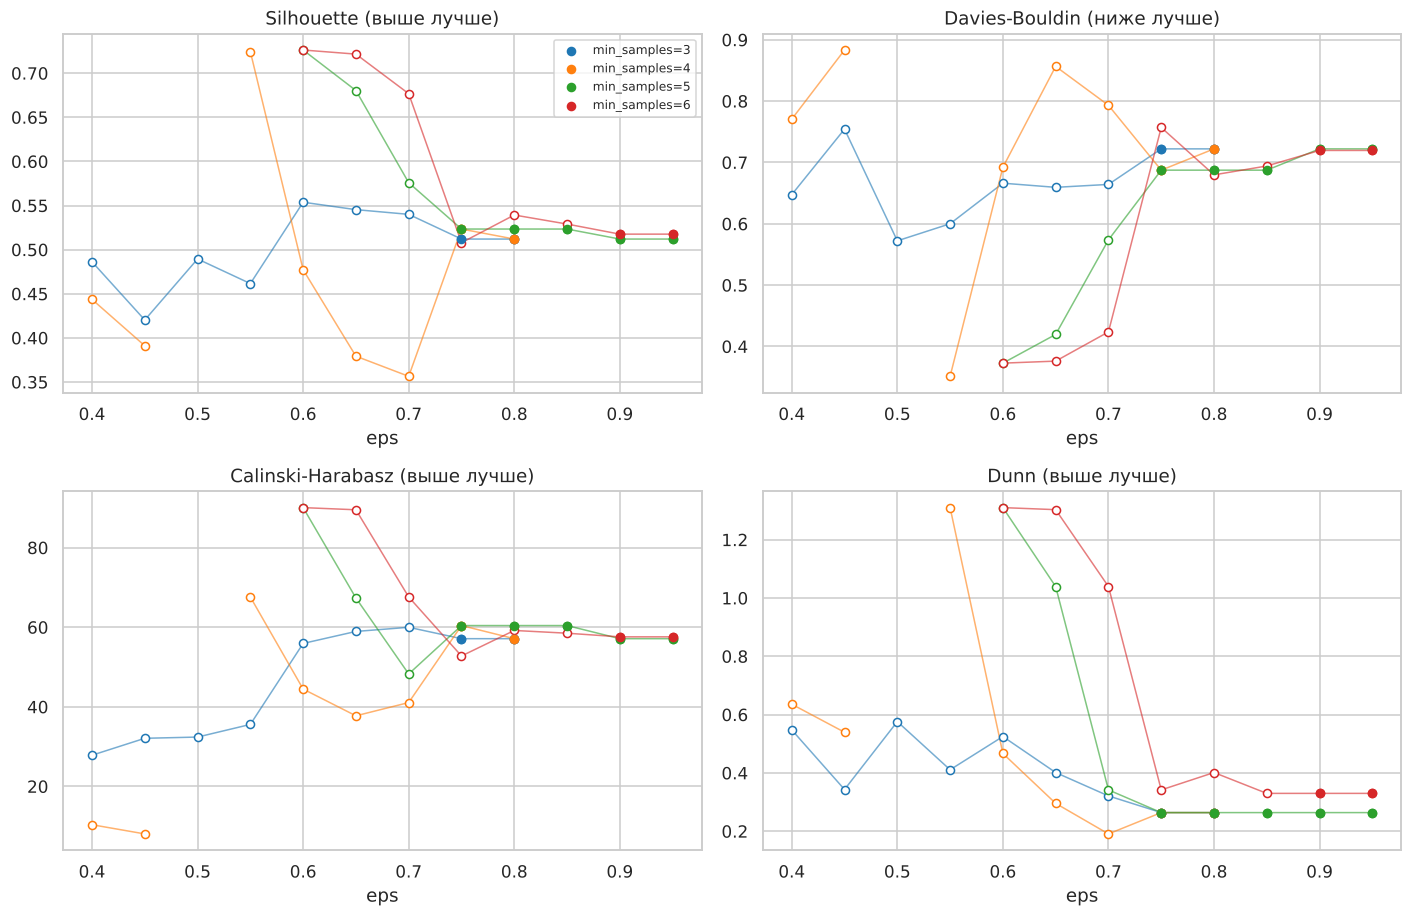

In [14]:
metric_titles = {
    'silhouette': 'Silhouette (выше лучше)',
    'davies_bouldin': 'Davies-Bouldin (ниже лучше)',
    'calinski_harabasz': 'Calinski-Harabasz (выше лучше)',
    'dunn': 'Dunn (выше лучше)',
}
colors = dict(zip(MIN_SAMPLES_GRID, sns.color_palette('tab10', 4)))
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, (column, title) in zip(axes.ravel(), metric_titles.items()):
    for min_samples, subset in grid.groupby('min_samples'):
        color = colors[min_samples]
        ax.plot(subset['eps'], subset[column], color=color, lw=1, alpha=0.6)
        ax.scatter(subset['eps'], subset[column], s=28, facecolor='white',
                   edgecolor=color, zorder=3)
        accepted = subset[subset['noise_share'] <= NOISE_LIMIT]
        ax.scatter(accepted['eps'], accepted[column], s=28, color=color,
                   zorder=4, label=f'min_samples={min_samples}')
    ax.set_title(title)
    ax.set_xlabel('eps')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Чтобы увидеть, чем опасен выбор по максимальной метрике, выводим решения с наибольшим Silhouette вместе с долей шума и размерами кластеров.

In [15]:
columns = ['eps', 'min_samples', 'n_clusters', 'n_noise', 'noise_share',
           'sizes'] + METRIC_COLUMNS
top = grid.dropna(subset=['silhouette']).nlargest(8, 'silhouette')
display(top[columns].round(3))

,eps,min_samples,n_clusters,n_noise,noise_share,sizes,silhouette,davies_bouldin,calinski_harabasz,dunn
56,0.60,5,2,28,0.609,12 / 6,0.726,0.373,90.060,1.310
81,0.60,6,2,28,0.609,12 / 6,0.726,0.373,90.060,1.310
30,0.55,4,2,30,0.652,12 / 4,0.724,0.351,67.594,1.310
82,0.65,6,2,27,0.587,13 / 6,0.722,0.376,89.517,1.303
57,0.65,5,2,25,0.543,15 / 6,0.680,0.420,67.347,1.039
83,0.70,6,2,24,0.522,16 / 6,0.677,0.424,67.603,1.039
58,0.70,5,3,21,0.457,16 / 6 / 3,0.576,0.574,48.257,0.342
6,0.60,3,2,16,0.348,16 / 14,0.554,0.666,55.929,0.525


Теперь отбираем решения, которые удовлетворяют заранее заданным условиям: не меньше двух кластеров, шум не более 20 %, в самом малом кластере не менее 5 городов. Одинаковые разбиения при соседних `eps` и `min_samples` сгруппированы: так видно, сколько существенно разных решений осталось и насколько широкая область параметров их порождает.

In [16]:
admissible = grid[
    (grid['n_clusters'] >= 2)
    & (grid['noise_share'] <= NOISE_LIMIT)
    & (grid['min_cluster_size'] >= MIN_CLUSTER_SIZE)
]
distinct = admissible.groupby('partition_id').agg(
    n_clusters=('n_clusters', 'first'),
    n_noise=('n_noise', 'first'),
    sizes=('sizes', 'first'),
    eps_min=('eps', 'min'),
    eps_max=('eps', 'max'),
    min_samples=('min_samples', lambda s: sorted(set(s))),
    n_settings=('eps', 'size'),
    silhouette=('silhouette', 'first'),
    davies_bouldin=('davies_bouldin', 'first'),
    calinski_harabasz=('calinski_harabasz', 'first'),
    dunn=('dunn', 'first'),
)
print(f'Допустимых сочетаний параметров: {len(admissible)}, '
      f'различных разбиений среди них: {len(distinct)}')
display(distinct.sort_values('n_settings', ascending=False).round(3))

Допустимых сочетаний параметров: 11, различных разбиений среди них: 3


,n_clusters,n_noise,sizes,eps_min,eps_max,min_samples,n_settings,silhouette,davies_bouldin,calinski_harabasz,dunn
partition_id,,,,,,,,,,,
9,2,8,19 / 19,0.75,0.95,"[3, 4, 5]",5,0.512,0.722,57.122,0.264
21,2,9,19 / 18,0.75,0.85,"[4, 5]",4,0.523,0.687,60.421,0.264
35,2,9,19 / 18,0.90,0.95,[6],2,0.518,0.720,57.585,0.330


Что показывают графики и таблицы.

- **Структура есть не везде.** Из 100 проверенных сочетаний только в 33 найдено два и более кластера. При малых `eps` почти все города становятся шумом (например, при `min_samples=5` и `eps=0,5` в шуме 36 городов из 46). При больших `eps` всё сливается в один кластер: для `min_samples` 3 и 4 это происходит уже при `eps=0,85` (один кластер из 38 городов и 8 шумовых).
- **Максимальные метрики получаются на шумных решениях.** Наибольший Silhouette (0,726) и Dunn (1,31) у решений с `eps=0,60` и `min_samples` 5 или 6: два кластера из 12 и 6 городов, а шум составляет 28 городов из 46 (61 %). Эти значения посчитаны на 18 городах, то есть на небольшой «чистой» части данных, и о структуре выборки в целом ничего не говорят. Выбор по максимуму Silhouette привёл бы именно к ним.
- **После отбора остаётся три разных разбиения.** Допустимыми по заданным условиям (два и более кластеров, шум не более 20 %, не менее 5 городов в малом кластере) оказались 11 сочетаний параметров, но разбиений среди них всего три, и все они двухкластерные: 19 / 19 (8 городов в шуме), 19 / 18 (9 в шуме, два диапазона параметров). Они отличаются друг от друга одним городом. Трёхкластерные решения встречаются только при шуме 24 % и выше (например, `min_samples=4`, `eps=0,70`: 17 / 14 / 4 при 11 городах в шуме) и в отбор не попадают: либо из-за доли шума, либо из-за малого кластера (у шести из семи таких решений он состоит из 3-4 городов).

Устойчивая плотностная структура в данных одна: две крупные группы по 18-19 городов и около 8-9 городов, не относящихся ни к одной из них. Деления на три кластера DBSCAN не поддерживает.

### Проверка варианта eps = 0.75, min_samples = 4

Сначала сверяем пересчёт с ориентировочными значениями предварительного расчёта, затем сравниваем этот вариант с ближайшими по `eps` и `min_samples`.

In [17]:
focus_row = grid[(grid['eps'] == FOCUS_EPS)
                 & (grid['min_samples'] == FOCUS_MIN_SAMPLES)].iloc[0]
reference = pd.Series({
    'silhouette': 0.523, 'davies_bouldin': 0.687,
    'calinski_harabasz': 60.421, 'dunn': 0.264,
})
print('Кластеров:', focus_row['n_clusters'],
      '| шумовых городов:', focus_row['n_noise'],
      '| размеры:', focus_row['sizes'])
print('Максимальное расхождение с предварительным расчётом:',
      (focus_row[METRIC_COLUMNS].astype(float).round(3)
       - reference).abs().max())

Кластеров: 2 | шумовых городов: 9 | размеры: 19 / 18
Максимальное расхождение с предварительным расчётом: 0.0


In [18]:
neighbor_eps = [0.65, 0.70, 0.75, 0.80, 0.85, 0.90]
neighbor_ms = [3, 4, 5]
neighbors = grid[grid['eps'].isin(neighbor_eps)
                 & grid['min_samples'].isin(neighbor_ms)]
display(neighbors.sort_values(['min_samples', 'eps'])[columns].round(3))

,eps,min_samples,n_clusters,n_noise,noise_share,sizes,silhouette,davies_bouldin,calinski_harabasz,dunn
7,0.65,3,2,13,0.283,17 / 16,0.545,0.659,58.940,0.401
8,0.70,3,2,11,0.239,18 / 17,0.540,0.664,59.984,0.321
9,0.75,3,2,8,0.174,19 / 19,0.512,0.722,57.122,0.264
10,0.80,3,2,8,0.174,19 / 19,0.512,0.722,57.122,0.264
11,0.85,3,1,8,0.174,38,NaN,NaN,NaN,NaN
12,0.90,3,1,8,0.174,38,NaN,NaN,NaN,NaN
32,0.65,4,3,15,0.326,16 / 11 / 4,0.379,0.857,37.740,0.296
33,0.70,4,3,11,0.239,17 / 14 / 4,0.356,0.793,41.070,0.191
34,0.75,4,2,9,0.196,19 / 18,0.523,0.687,60.421,0.264
35,0.80,4,2,8,0.174,19 / 19,0.512,0.722,57.122,0.264


**Результат для eps = 0.75, min_samples = 4.** Найдено два кластера (19 и 18 городов) и 9 шумовых городов, то есть 19,6 % выборки: вариант проходит порог 20 %, но с минимальным запасом. Метрики на 37 не-шумовых городах: Silhouette 0,523, Davies-Bouldin 0,687, Calinski-Harabasz 60,421, Dunn 0,264. Расхождение с предварительным расчётом нулевое.

**Сравнение с ближайшими альтернативами.**

- `eps=0,80`, `min_samples=4`: два кластера 19 / 19 и 8 городов в шуме. Метрики немного хуже (Silhouette 0,512, Davies-Bouldin 0,722, Calinski-Harabasz 57,1), Dunn такой же (0,264). Различие сводится к одному городу, и считать один вариант лучшим по сути нельзя.
- `eps=0,85` и выше при `min_samples` 3 и 4: все не-шумовые города сливаются в один кластер из 38 городов, метрики не определены. Структура пропадает сразу за границей области.
- `eps=0,70`, `min_samples=4`: три кластера 17 / 14 / 4, но шум 11 городов (24 %), Silhouette 0,356. Малый кластер из четырёх городов нельзя отличить от случайной группы.
- `min_samples=5` при `eps` от 0,75 до 0,85 даёт то же разбиение, что и основной вариант (19 / 18, 9 шумовых, те же метрики). При `min_samples=3` и `eps=0,75` получается решение 19 / 19 с 8 шумовыми городами.

Вывод: два кластера воспроизводятся на заметной части сетки (примерно `eps` 0,75-0,90 при трёх-пяти соседях), поэтому как структура они надёжны. Но состав шума (8 или 9 городов) и само наличие кластеров чувствительны к `eps` в пределах 0,05-0,10, и вариант `eps=0,75`, `min_samples=4` находится у края устойчивой области, а не в её середине. При `min_samples=5` то же разбиение сохраняется дальше, вплоть до `eps=0,85`.

## 9. Интерпретация результатов

### Итоговое разбиение для eps = 0.75, min_samples = 4

Профили кластеров считаются в исходных единицах, шумовые города выделены отдельно: именно они показывают, что алгоритм счёл нетипичным.

In [19]:
final_labels = partitions[(FOCUS_EPS, FOCUS_MIN_SAMPLES)]
in_cluster = final_labels != -1

display(cluster_profile(clean[in_cluster], final_labels[in_cluster]))
print_cities(clean, final_labels)
print()
noise_table = clean[~in_cluster].set_index('City')[FEATURES]
print('Шумовые города (значения в исходных единицах):')
display(noise_table)
print('Для сравнения, средние по всей выборке:')
display(clean[FEATURES].mean().round(1).to_frame('mean').T)

,n,Work_mean,Price_mean,Salary_mean,Work_median,Price_median,Salary_median
cluster,,,,,,,
1,19,1959.2,50.1,14.8,1958.0,49.2,11.5
2,18,1776.7,77.4,54.6,1751.5,75.2,52.7


  Шум (9): Geneva, Helsinki, Hong Kong, Los Angeles, Oslo, Stockholm, Taipei, Tokyo, Zurich
  Кластер 1 (19): Athens, Bogota, Bombay, Buenos Aires, Caracas, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Tel Aviv
  Кластер 2 (18): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Luxembourg, Madrid, Milan, Montreal, New York, Paris, Sydney, Toronto, Vienna

Шумовые города (значения в исходных единицах):


,Work,Price,Salary
City,,,
Geneva,1880.0,95.9,90.3
Helsinki,1667.0,113.6,66.6
Hong_Kong,2375.0,63.8,27.8
Los_Angeles,2068.0,79.8,65.2
Oslo,1583.0,115.5,63.7
Stockholm,1805.0,111.3,39.2
Taipei,2145.0,84.3,34.5
Tokyo,1880.0,115.0,68.0
Zurich,1868.0,100.0,100.0


Для сравнения, средние по всей выборке:


,Work,Price,Salary
mean,1879.9,70.1,39.5


Метрики DBSCAN рассчитаны на не-шумовых городах, поэтому прямое сравнение с K-means на всех городах было бы несправедливым. Для честного сопоставления берём K-means с `k=2` (50 запусков) и считаем те же метрики на том же множестве не-шумовых городов. Если DBSCAN действительно находит иную структуру, чем K-means, это отразится в ARI.

In [20]:
kmeans_labels = relabel_by_salary(
    KMeans(n_clusters=2, n_init=50,
           random_state=RANDOM_STATE).fit_predict(X),
    clean['Salary'].values,
)
dbscan_metrics = evaluate_partition(X[in_cluster], final_labels[in_cluster])
kmeans_metrics = evaluate_partition(X[in_cluster], kmeans_labels[in_cluster])
comparison = pd.DataFrame([dbscan_metrics, kmeans_metrics],
                          index=['DBSCAN (eps=0.75, ms=4)',
                                 'K-means (k=2)']).round(3)
display(comparison)
ari = adjusted_rand_score(final_labels[in_cluster],
                          kmeans_labels[in_cluster])
print(f'ARI между DBSCAN и K-means на не-шумовых городах: {ari:.3f}')

all_cities = evaluate_partition(X, kmeans_labels)
print('K-means (k=2) на всех 46 городах:',
      {name: round(float(value), 3) for name, value in all_cities.items()})
print('Куда K-means отнёс шумовые города DBSCAN:')
print_cities(clean[~in_cluster], kmeans_labels[~in_cluster])

,silhouette,davies_bouldin,calinski_harabasz,dunn
"DBSCAN (eps=0.75, ms=4)",0.523,0.687,60.421,0.264
K-means (k=2),0.523,0.687,60.421,0.264


ARI между DBSCAN и K-means на не-шумовых городах: 1.000
K-means (k=2) на всех 46 городах: {'silhouette': 0.47, 'davies_bouldin': 0.808, 'calinski_harabasz': 55.351, 'dunn': 0.223}
Куда K-means отнёс шумовые города DBSCAN:
  Кластер 1 (2): Hong Kong, Taipei
  Кластер 2 (7): Geneva, Helsinki, Los Angeles, Oslo, Stockholm, Tokyo, Zurich


Визуализация итогового разбиения в плоскости двух главных компонент (кластеризация выполнена на трёх признаках) и боксплоты по кластерам. Шумовые города отмечены серыми крестами.

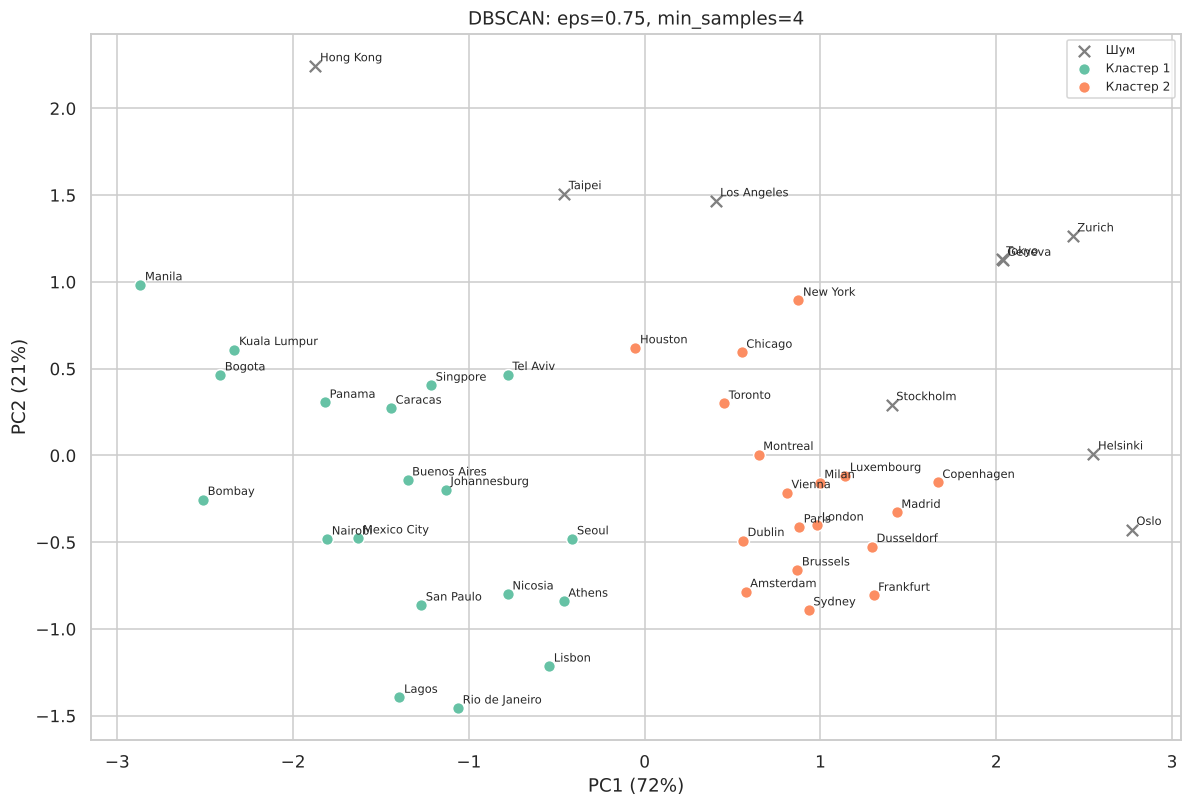

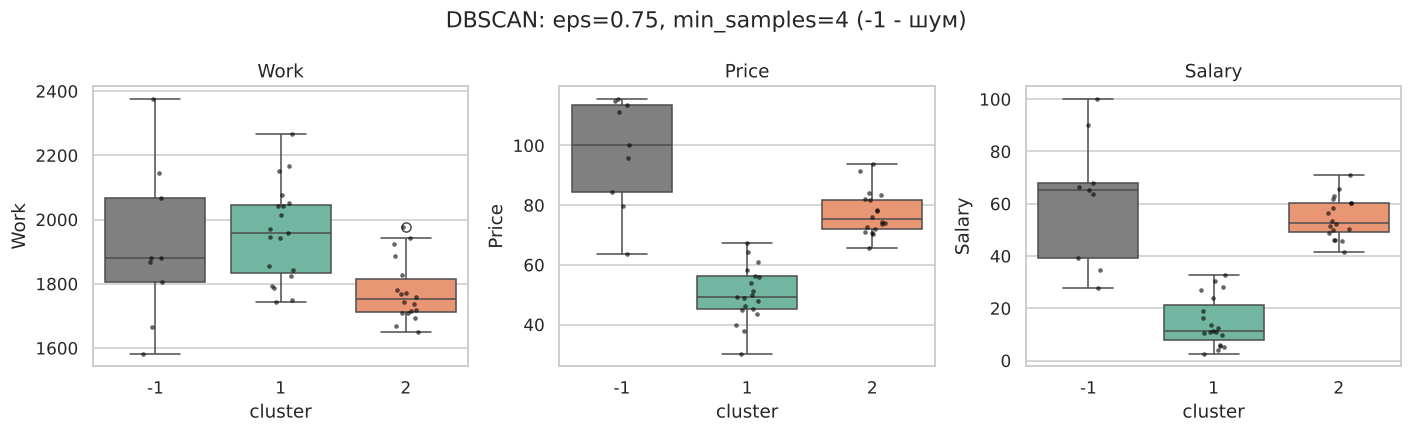

In [21]:
fig, ax = plt.subplots(figsize=(11, 7.5))
plot_clusters(ax, final_labels, 'DBSCAN: eps=0.75, min_samples=4')
plt.tight_layout()
plt.show()
plot_feature_boxes(final_labels, 'DBSCAN: eps=0.75, min_samples=4 (-1 - шум)')

**Кластеры.** Кластер 1 (19 городов): `Work` 1959, `Price` 50,1, `Salary` 14,8 (медианы 1958, 49,2 и 11,5) - дешёвые и малооплачиваемые города с большой рабочей нагрузкой. Кластер 2 (18 городов): `Work` 1777, `Price` 77,4, `Salary` 54,6 (медианы 1752, 75,2 и 52,7) - дорогие и высокооплачиваемые города. Группы сбалансированы по размеру (19 и 18).

**Шум.** В шум попали девять городов: Женева, Хельсинки, Гонконг, Лос-Анджелес, Осло, Стокгольм, Тайбэй, Токио и Цюрих. Шесть из них (Женева, Хельсинки, Осло, Стокгольм, Токио, Цюрих) имеют цены 95,9-115,5, то есть выше любого города из кластеров, а Цюрих и Женева ещё и самую высокую зарплату (100 и 90,3). Гонконг, Тайбэй и Лос-Анджелес отличаются длинной рабочей нагрузкой (2375, 2145 и 2068 часов). Иными словами, DBSCAN убрал из кластеров крайние города по ценам, зарплатам или рабочему времени, а не нашёл в данных дополнительных групп.

**Честное сопоставление с K-means.** На тех же 37 не-шумовых городах K-means с двумя кластерами даёт идентичное разбиение (ARI равен 1) и совпадающие метрики. То есть улучшение Silhouette с 0,470 (K-means на всех 46 городах) до 0,523 целиком объясняется тем, что DBSCAN исключил девять самых трудных для разбиения городов, а не более удачной структурой. K-means относит семь из девяти шумовых городов к «дорогой» группе, а Гонконг и Тайбэй к «дешёвой».

## 10. Итоговые выводы

**Наиболее обоснованное решение.** DBSCAN находит единственную устойчивую структуру: две группы по 18-19 городов (дорогие и высокооплачиваемые против дешёвых и малооплачиваемых) и 8-9 городов, которые не отнесены ни к одной из них. В качестве итогового варианта принят `eps=0,75`, `min_samples=4` (19 и 18 городов, 9 шумовых), сравнение с ближайшими вариантами показало, что `eps=0,80` даёт практически то же решение с 8 шумовыми городами.

**Почему.** Это решение входит в область параметров, где повторяется одно и то же двухкластерное разбиение, и проходит условия, заданные заранее: два кластера, шум 19,6 % (не более 20 %), малый кластер из 18 городов. Выбор не делался по максимуму Silhouette: наибольшие значения (Silhouette до 0,726) относятся к решениям с шумом 54-65 %.

**Какие метрики поддерживают выбор.** Silhouette 0,523, Davies-Bouldin 0,687, Calinski-Harabasz 60,421 и Dunn 0,264 выше, чем у двухкластерных решений Ward и K-means на всех городах (0,470, 0,808, 55,35, 0,223). Но эти метрики **рассчитаны только на не-шумовых наблюдениях** (37 из 46 городов) и сравнивать их с метриками на полной выборке нельзя. На тех же 37 городах K-means с двумя кластерами даёт идентичное разбиение и идентичные значения, поэтому метрики не подтверждают превосходства DBSCAN над K-means.

**Какие метрики противоречат.** Прямых противоречий нет: все четыре метрики для выбранного решения согласованы. Но у других сочетаний параметров Silhouette и Dunn выше, чем у выбранного, при этом доля шума достигает 54-65 %, и это тот случай, когда метрики вводят в заблуждение.

**Баланс.** Кластеры 19 и 18 городов сбалансированы. Девять городов (20 % выборки) остаются без группы, это неизбежная цена метода.

**Что отличает кластеры.** Как и у остальных методов, различие создают зарплата и цены: `Salary` 54,6 против 14,8 и `Price` 77,4 против 50,1 в «дорогой» и «дешёвой» группах, рабочая нагрузка ниже в «дорогой» (1777 против 1959 часов). Шум образуют крайние города: самые дорогие и высокооплачиваемые (Цюрих, Женева, Осло, Хельсинки, Стокгольм, Токио) и города с самой длинной рабочей нагрузкой (Гонконг, Тайбэй, Лос-Анджелес).

**Устойчивость структуры.** Двухгрупповая структура устойчива в области `eps` около 0,75-0,90 при трёх-пяти соседях. Трёхкластерных решений, которые бы выдерживали ограничение по доле шума и размеру кластера, нет. Более детальной устойчивой структуры DBSCAN в этих данных не находит: плотность в выборке из 46 городов слишком неравномерна, чтобы один радиус `eps` описывал её тоньше. Если нужна детальная сегментация на три группы, для этого подходят иерархическая кластеризация и K-means, но не DBSCAN.

**Ограничения.** Они перечислены в следующем разделе: единый `eps`, чувствительность к параметрам, несопоставимость метрик, часть городов остаётся без группы.

## 11. Ограничения метода

- Единый `eps` предполагает близкую плотность всех кластеров. В данных о городах плотность неоднородна: «дешёвые» города разбросаны, а «дорогие» расположены плотнее или наоборот, и один радиус не годится для обоих случаев.
- Результат чувствителен к параметрам: небольшое изменение `eps` или `min_samples` способно превратить один кластер в два или половину города в шум. На 46 наблюдениях эта чувствительность выражена сильнее обычного.
- Метрики качества рассчитываются только на не-шумовых городах, поэтому они завышены относительно метрик методов, которые разбивают все объекты. Сравнивать их напрямую нельзя.
- Метод не даёт кластеров для городов, которые считаются шумом. Для прикладной сегментации это означает, что часть городов остаётся без группы.
- Silhouette, Davies-Bouldin и Calinski-Harabasz по построению благоволят компактным выпуклым кластерам, а DBSCAN их не ищет. Поэтому внутренние метрики недооценивают то, ради чего DBSCAN используется. Dunn определяется двумя экстремальными расстояниями.
- Каир и Джакарта исключены из-за пропусков и в анализе не представлены.
- Данные относятся к 1991 году и включают только три признака, поэтому выводы описывают структуру тех лет.